## 1: Imports and Parameters
Install and import the necessary libraries (numpy, pandas, networkx, pyplot) and define the main parameters of the model

In [ ]:
# Install the libraries

%pip install numpy
%pip install pandas 
%pip install networkx
%pip install matplotlib


[notice] A new release of pip is available: 25.2 -> 26.2.1
[notice] To update, run: pip install --upgrade pip
Note: you may need to restart the kernel to use updated packages.

[notice] A new release of pip is available: 25.2 -> 26.2.1
[notice] To update, run: pip install --upgrade pip
Note: you may need to restart the kernel to use updated packages.

[notice] A new release of pip is available: 25.2 -> 26.2.1
[notice] To update, run: pip install --upgrade pip
Note: you may need to restart the kernel to use updated packages.

[notice] A new release of pip is available: 25.2 -> 26.2.1
[notice] To update, run: pip install --upgrade pip
Note: you may need to restart the kernel to use updated packages.


In [4]:
# Import the libraries

import matplotlib.pyplot as plt
import networkx as nx
import numpy as np
import pandas as pd


In [5]:
# Define the main parameters

# Number of nodes
N = 10000

# Parameter c (average number of links for each node)
c = 0.95

# Parameter p (probability that a node is linked to another)
p = c/N

# Parameter lambda (proxy for market depth)
lam = 1

## 2: Random Graph Generation
Generate the Random Graph with the parameters above

In [6]:
G = nx.fast_gnp_random_graph(N, p)

In [7]:
print("Number of nodes:", G.number_of_nodes())
print("Number of edges:", G.number_of_edges())
print("Average degree:", sum(dict(G.degree()).values())/N) 

Number of nodes: 10000
Number of edges: 4717
Average degree: 0.9434


## 3: Connected Components Identification
Identification of the graphs connected components

In [8]:
# Visualize the graph's connected components

components = list(nx.connected_components(G))
n_components = len(components)  

print("Number of connected components:", n_components)

cluster_sizes = []

for component in components:
    cluster_sizes.append(len(component))

print("Sizes of connected components:", cluster_sizes)
print("Average size of connected components:", np.mean(cluster_sizes))
print("Largest connected component size:", max(cluster_sizes))

#Check
#print("Sum of sizes of connected components:", sum(cluster_sizes))


Number of connected components: 5284
Sizes of connected components: [2, 24, 10, 1, 2, 2, 1, 1, 3, 19, 4, 1, 8, 1, 35, 117, 1, 1, 1, 1, 8, 91, 3, 1, 1, 1, 5, 26, 101, 1, 12, 12, 5, 2, 24, 1, 1, 5, 48, 4, 1, 3, 1, 2, 2, 1, 5, 3, 1, 10, 2, 3, 1, 2, 2, 4, 7, 21, 1, 2, 1, 5, 1, 2, 1, 1, 1, 3, 1, 1, 22, 2, 46, 6, 7, 7, 4, 42, 8, 3, 2, 1, 14, 1, 1, 7, 5, 1, 8, 18, 1, 2, 1, 4, 1, 1, 1, 4, 1, 2, 1, 10, 27, 1, 3, 1, 1, 1, 1, 1, 8, 3, 6, 1, 3, 5, 13, 1, 2, 15, 1, 1, 1, 2, 9, 5, 1, 9, 3, 1, 2, 79, 2, 1, 3, 1, 1, 1, 70, 1, 1, 1, 6, 2, 1, 1, 6, 1, 1, 2, 7, 1, 1, 3, 7, 48, 10, 1, 8, 2, 1, 2, 1, 1, 6, 1, 3, 28, 7, 2, 2, 2, 5, 20, 1, 1, 3, 1, 1, 1, 2, 2, 1, 1, 1, 1, 1, 1, 2, 1, 1, 5, 1, 1, 1, 4, 8, 5, 2, 4, 1, 30, 7, 3, 3, 7, 6, 1, 3, 5, 2, 1, 1, 1, 1, 1, 1, 1, 1, 1, 2, 4, 7, 2, 3, 1, 1, 3, 1, 18, 1, 1, 6, 31, 3, 6, 18, 1, 2, 1, 2, 2, 1, 2, 1, 4, 1, 11, 1, 1, 1, 1, 5, 2, 1, 1, 2, 1, 3, 1, 2, 1, 6, 2, 1, 1, 8, 1, 5, 1, 1, 6, 4, 1, 1, 2, 11, 2, 3, 4, 2, 1, 1, 25, 4, 2, 1, 2, 1, 7, 1, 2, 3, 1, 1, 1, 1, 1,

## 4: One Period Market Simulation
Here we simulate the creation of opinions between clusters, and therefore the market aggregate demand 

In [9]:
# First we need to set the parameter a, s.t. 2a is the prob. that the node is active
# Thus, 0 < a < 0.5

a = 0.4

In [10]:
# Draw decision for each connected component, i.e. if the component is buying,
# selling or inactive

cluster_decisions = np.random.choice([-1, 0, 1], size=n_components, p=[a, 1-2*a, a])

cluster_contributes = cluster_decisions*np.array(cluster_sizes)

#type check
#print(type(cluster_decisions), type (np.array(cluster_sizes)), type(cluster_contributes))

print("Cluster contributes:", cluster_contributes)

D = sum(cluster_contributes)

print("Aggregate demand D:", D)

Cluster contributes: [ -2 -24 -10 ...   1   1  -1]
Aggregate demand D: 181


## 5: Repeated experiment
Here we repeat the previous model multiple times

In [25]:
# We now define a functions that computes the one period market simulation 
# and returns the aggregate demand D, given the parameters N, c and a

def one_period_simulation(N, c, a, lam):
    p = c/N
    G = nx.fast_gnp_random_graph(N, p)
    components = list(nx.connected_components(G))
    n_components = len(components)  
    cluster_sizes = [len(component) for component in components]
    cluster_decisions = np.random.choice([-1, 0, 1], size=n_components, p=[a, 1-2*a, a])
    cluster_contributes = cluster_decisions*np.array(cluster_sizes)
    D = sum(cluster_contributes)
    delta_x = D/lam

    results = pd.DataFrame({
        'Price Change': [delta_x],
        'Aggregate Demand': [D],
        'Number of Clusters': [n_components],
        'Active Clusters': [np.sum(abs(cluster_decisions))],
        'Largest Cluster': [max(cluster_sizes)],
    })

    return results

print(one_period_simulation(N, c, a, lam))


   Price Change  Aggregate Demand  Number of Clusters  Active Clusters  \
0         -16.0               -16                 527              211   

   Largest Cluster  
0               33  


In [26]:
# Now we define a function that computes the market simulation for T periods and returns 
# a DataFrame with the results for each period

T = 10_000

N = 1000
c = 0.95
a = 0.2
lam = 1

def market_simulation(T, N, c, a, lam):
    for t in range(T):
        results = one_period_simulation(N, c, a, lam)
        if t == 0:
            df_results = results
        else:
            df_results = pd.concat([df_results, results], ignore_index=True)
    return df_results        

#print(market_simulation(T, N, c, a, lam))

In [27]:
# Let's visualize mean results of the market simulation for T periods

mean_results = market_simulation(T, N, c, a, lam).mean()

In [32]:
print(f"Mean results over {T:,} periods:\n")
print(mean_results)

Mean results over 10,000 periods:

Price Change           -0.2151
Aggregate Demand       -0.2151
Number of Clusters    526.3741
Active Clusters       210.4997
Largest Cluster        69.1710
dtype: float64


## 6: Independent Agent Benchmark

In [33]:
# Now let's simulate the results for c = 0
# This simulates the case where there are no links between the nodes, 
# i.e. each node is isolated and makes its own decision independently of the others

c = 0

mean_results = market_simulation(T, N, c, a, lam).mean()
print(f"Mean results over {T:,} periods:\n")
print(mean_results)

Mean results over 10,000 periods:

Price Change             0.3419
Aggregate Demand         0.3419
Number of Clusters    1000.0000
Active Clusters        400.1243
Largest Cluster          1.0000
dtype: float64


## 7: Effect of c 

In [34]:
# Now let's simulate what happens when c is higher than the critical value 1,
# i.e., when the nodes are connected to more than one other node on average

c = 1.5

mean_results = market_simulation(T, N, c, a, lam).mean()
print(f"Mean results over {T:,} periods:\n")
print(mean_results)

Mean results over 10,000 periods:

Price Change            2.3708
Aggregate Demand        2.3708
Number of Clusters    288.2720
Active Clusters       115.2898
Largest Cluster       578.7964
dtype: float64


## 8: Return distribution
In this section we analyze the distribution of returns in the Cont-Bucheaud model, and we compare it with the normally distributed returns we would expect from classical theory

In [35]:
T = 10_000

N = 1000
c = 0.95
a = 0.2
lam = 1

results = market_simulation(T, N, c, a, lam)

returns = results['Price Change'].values

print(results.describe())

       Price Change  Aggregate Demand  Number of Clusters  Active Clusters  \
count  10000.000000      10000.000000        10000.000000     10000.000000   
mean       0.817700          0.817700          526.342900       210.557000   
std       67.819055         67.819055           21.799331        14.307775   
min     -282.000000       -282.000000          435.000000       160.000000   
25%      -39.000000        -39.000000          512.000000       201.000000   
50%        1.000000          1.000000          527.000000       211.000000   
75%       41.000000         41.000000          541.000000       220.000000   
max      279.000000        279.000000          609.000000       262.000000   

       Largest Cluster  
count     10000.000000  
mean         69.061400  
std          37.419143  
min          13.000000  
25%          42.000000  
50%          59.000000  
75%          86.000000  
max         301.000000  


In [39]:
# Let's compute the excess kurtosis of the returns distribution

print("Excess kurtosis of the returns distribution:", pd.Series(returns).kurt())

# An excess kurtosis greater than 0 indicates that the distribution has heavier tails 
# than a normal distribution, which is a common feature of financial returns.

Excess kurtosis of the returns distribution: 0.800599132265793


Text(0, 0.5, 'Density')

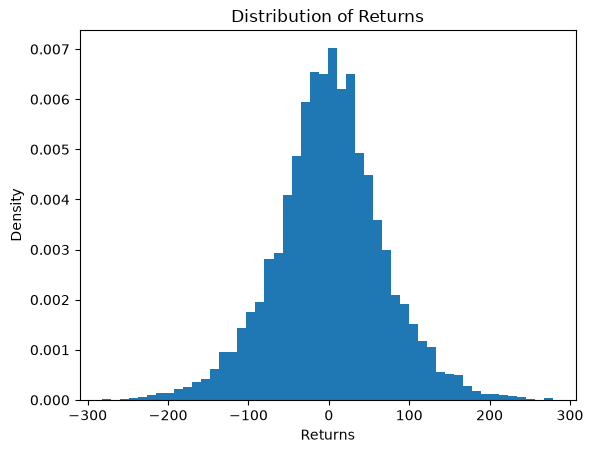

In [40]:
# Now let's visualize the distribution of returns for the market simulation

#plt.figure()

plt.hist(returns, bins=50, density=True)
plt.title("Distribution of Returns")
plt.xlabel("Returns")
plt.ylabel("Density")

#plt.show()

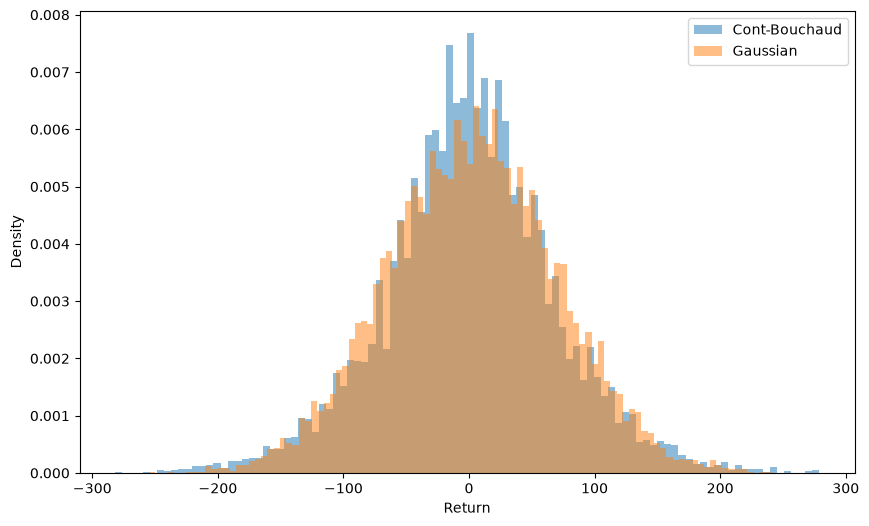

In [41]:
# Let's compare it to a normal distribution with the same mean and standard deviation

# Lets generate a normal distribution with the same mean and standard deviation as the returns
gaussian_returns = np.random.normal(
    loc=returns.mean(),
    scale=returns.std(),
    size=len(returns)
)

# Now let's plot them together

plt.figure(figsize=(10, 6))

plt.hist(
    returns,
    bins=100,
    density=True,
    alpha=0.5,
    label="Cont-Bouchaud"
)

plt.hist(
    gaussian_returns,
    bins=100,
    density=True,
    alpha=0.5,
    label="Gaussian"
)

plt.xlabel("Return")
plt.ylabel("Density")
plt.legend()
plt.show()


In [42]:
# Let's better visualize the tails of the distribution by confronting
# the empirical quatiles of the absolute returns of the two models

standardized_returns = (returns - returns.mean()) / returns.std()
standardized_gaussian_returns = (gaussian_returns - gaussian_returns.mean()) / gaussian_returns.std()

std_returns_abs = np.abs(standardized_returns)
std_gaussian_returns_abs = np.abs(standardized_gaussian_returns)

returns_quantiles = np.quantile(std_returns_abs, [0.9, 0.95, 0.99, 0.999])
gaussian_returns_quantiles = np.quantile(std_gaussian_returns_abs, [0.9, 0.95, 0.99, 0.999])   

print("Empirical quantiles of the absolute returns of the Cont-Bouchaud model:", returns_quantiles)
print(f"Empirical quantiles of the absolute returns of the Gaussian model: {gaussian_returns_quantiles}")


Empirical quantiles of the absolute returns of the Cont-Bouchaud model: [1.66359354 2.04698579 2.9171925  3.63955296]
Empirical quantiles of the absolute returns of the Gaussian model: [1.64088963 1.9558669  2.57613597 3.20846405]


In [43]:
# Now let's see how the tails change when we increase the parameter c, 
# and compare them to the Gaussian model with the same mean and standard deviation

c_values = [0.5, 0.75, 0.9, 0.95, 0.99, 0.999]

for c in c_values:
    results = market_simulation(T, N, c, a, lam)
    returns = results['Price Change'].values
    standardized_returns = (returns - returns.mean()) / returns.std()
    std_returns_abs = np.abs(standardized_returns)
    returns_quantiles = np.quantile(std_returns_abs, [0.9, 0.95, 0.99, 0.999])

    gaussian_returns = np.random.normal(
    loc=returns.mean(),
    scale=returns.std(),
    size=len(returns)
    )
    standardized_gaussian_returns = (gaussian_returns - gaussian_returns.mean()) / gaussian_returns.std()
    std_gaussian_returns_abs = np.abs(standardized_gaussian_returns)
    gaussian_returns_quantiles = np.quantile(std_gaussian_returns_abs, [0.9, 0.95, 0.99, 0.999])

    print(f"Quantiles of the absolute returns of the Cont-Bouchaud model for c={c}: {returns_quantiles}")
    print(f"Quantiles of the absolute returns of the Gaussian model for c={c}: {gaussian_returns_quantiles}\n")

Quantiles of the absolute returns of the Cont-Bouchaud model for c=0.5: [1.62692157 1.94422934 2.64935772 3.42499895]
Quantiles of the absolute returns of the Gaussian model for c=0.5: [1.6590855  1.96144393 2.52150408 3.24144037]

Quantiles of the absolute returns of the Cont-Bouchaud model for c=0.75: [1.64949276 1.97974299 2.64625468 3.43655088]
Quantiles of the absolute returns of the Gaussian model for c=0.75: [1.63836773 1.92603453 2.50830106 3.18318578]

Quantiles of the absolute returns of the Cont-Bouchaud model for c=0.9: [1.6338294  2.00292173 2.79400963 3.5686325 ]
Quantiles of the absolute returns of the Gaussian model for c=0.9: [1.64538345 1.95029744 2.52019869 3.25555093]

Quantiles of the absolute returns of the Cont-Bouchaud model for c=0.95: [1.64767145 2.03458083 2.87625819 3.87325753]
Quantiles of the absolute returns of the Gaussian model for c=0.95: [1.63936819 1.94458656 2.58488397 3.44573253]

Quantiles of the absolute returns of the Cont-Bouchaud model for c=0

In [44]:
# Now let's store relevant values for each vale of c in a DataFrame and visualize them

c_values = [0.5, 0.75, 0.9, 0.95, 0.99, 0.999]

for c in c_values:
    results = market_simulation(T, N, c, a, lam)
    returns = results['Price Change'].values
    standardized_returns = (returns - returns.mean()) / returns.std()
    std_returns_abs = np.abs(standardized_returns)
    returns_quantiles = np.quantile(std_returns_abs, [0.9, 0.95, 0.99, 0.999])

    returns_mean = returns.mean()
    returns_std = returns.std()
    returns_kurt = pd.Series(returns).kurt()
    

    df_results = pd.DataFrame({
        'c': c,
        'Mean': returns_mean,
        'Std': returns_std,
        'Excess Kurtosis': returns_kurt,
        '90% quantile': returns_quantiles[0],
        '95% quantile': returns_quantiles[1],
        '99% quantile': returns_quantiles[2],
        '99.9% quantile': returns_quantiles[3],
    }, index=[0])

    if c == c_values[0]:
        df_all_results = df_results
    else:
        df_all_results = pd.concat([df_all_results, df_results], ignore_index=True)

In [45]:
# Here we can visualize the results in a table and compare them to the Gaussian model 

print(df_all_results)

gaussian_returns = np.random.normal(
    loc=returns.mean(),
    scale=returns.std(),
    size=len(returns)
)

standardized_gaussian_returns = (gaussian_returns - gaussian_returns.mean()) / gaussian_returns.std()
std_gaussian_returns_abs = np.abs(standardized_gaussian_returns)
gaussian_returns_quantiles = np.quantile(std_gaussian_returns_abs, [0.9, 0.95, 0.99, 0.999])

print('\n\n')

print(f"Quantiles of the absolute returns of the Gaussian model: {gaussian_returns_quantiles}\n")

       c    Mean        Std  Excess Kurtosis  90% quantile  95% quantile  \
0  0.500 -0.1655  27.833457         0.058330      1.622705      1.970093   
1  0.750 -0.4878  39.630098         0.177009      1.652476      1.955892   
2  0.900  0.2118  57.456900         0.626400      1.639695      2.022591   
3  0.950 -0.3812  67.092689         0.721430      1.660109      2.051174   
4  0.990 -0.1307  79.337082         1.116136      1.690643      2.090691   
5  0.999 -0.5885  82.723050         0.977113      1.709457      2.122607   

   99% quantile  99.9% quantile  
0      2.592761        3.299500  
1      2.636583        3.393578  
2      2.781083        3.797904  
3      2.852490        3.631104  
4      2.947826        3.770516  
5      2.920549        3.667799  



Quantiles of the absolute returns of the Gaussian model: [1.6381691  1.94695348 2.62754992 3.34183177]

